In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import FormatStrFormatter
import rioxarray as rxr
from sklearn.decomposition import PCA
from sklearn import cluster
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
from scipy.stats import mode
from scipy.ndimage import generic_filter

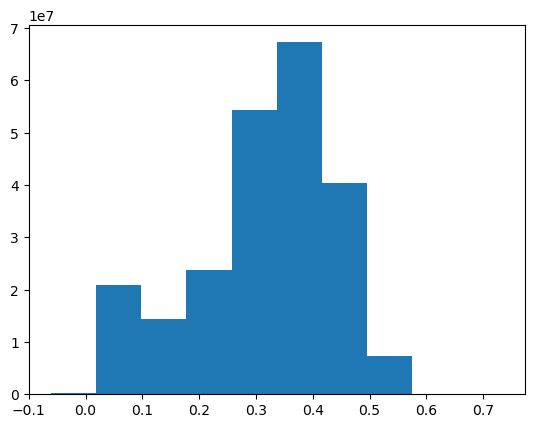

In [24]:
# load the data 
#(rioxarray library that opens raster/geospatial image files (like GeoTIFF, NetCDF, etc.) 
# and loads them as xarray DataArrays with geospatial metadata intact.)
# .squeeze() removes dimensions of size 1 from an array or DataArray.
data_enmap = rxr.open_rasterio('Datasets/ENMAP01-____L2A-DT0000160657_20251016T011429Z_002_V010502_20251017T031330Z-SPECTRAL_IMAGE.TIF').squeeze()

# Replace fill values with NaN
data_enmap = data_enmap.where(data_enmap != -32768)

# Scale to reflectance (0-1 range) - scaled by 10000
data_enmap = data_enmap / 10000.0

data_enmap.plot()
plt.title('')
plt.show()

In [25]:
# Get the spatial extent for plotting
extent = [data_enmap.x.min().values, data_enmap.x.max().values,
          data_enmap.y.min().values, data_enmap.y.max().values]

extent

[array(567090.), array(603750.), array(6712260.), array(6747690.)]

In [26]:
# Get the shape
if len(data_enmap.shape) == 3:
    bands, rows, cols = data_enmap.shape
else:
    raise ValueError(f"Expected 3D data (bands, rows, cols), got shape {data_enmap.shape}")

# Reshape to 2D: (n_pixels, n_bands)
data_reshaped = data_enmap.values.reshape(bands, -1).T
print(f"Reshaped to: {data_reshaped.shape} (pixels × bands)")

Reshaped to: (1445586, 224) (pixels × bands)


In [27]:
# Step 1: Identify bands with valid data
bands_with_data = []
bands_without_data = []

for band_idx in range(bands):
    band_mean = np.nanmean(data_reshaped[:, band_idx])
    if not np.isnan(band_mean):
        bands_with_data.append(band_idx)
    else:
        bands_without_data.append(band_idx)

print(f"Bands with valid data: {len(bands_with_data)} out of {bands}")
print(f"Bands with NO valid data: {len(bands_without_data)}")

if len(bands_without_data) > 0:
    if len(bands_without_data) <= 20:
        print(f"Problematic bands removed: {bands_without_data}")
    else:
        print(f"First 20 problematic bands: {bands_without_data[:20]}")
        print(f"... and {len(bands_without_data) - 20} more")

# Step 2: Keep only valid bands
data_reshaped_valid_bands = data_reshaped[:, bands_with_data]
print(f"New data shape: {data_reshaped_valid_bands.shape}")
print(f"Removed {len(bands_without_data)} invalid bands")

# Step 3: Fill remaining NaN values with band means
data_reshaped_filled = data_reshaped_valid_bands.copy()
print("Filling NaN values with band means...")

total_nans_filled = 0
for i, band_idx in enumerate(bands_with_data):
    band_data = data_reshaped_filled[:, i]
    nan_count = np.isnan(band_data).sum()
    
    if nan_count > 0:
        band_mean = np.nanmean(band_data)
        data_reshaped_filled[:, i] = np.where(np.isnan(band_data), band_mean, band_data)
        total_nans_filled += nan_count
        
        if i % 50 == 0 or i < 5:  # Print first 5 bands and every 50th band
            print(f"  Band {i} (original band {band_idx}): Filled {nan_count} NaNs with mean {band_mean:.4f}")

print(f"\nTotal NaN values filled: {total_nans_filled:,}")

# Step 4: Remove completely invalid pixels (all NaN in original data)
# Check how many NaNs each pixel had in the original data
nan_count_per_pixel = np.isnan(data_reshaped).sum(axis=1)
completely_invalid = nan_count_per_pixel == bands
data_valid = data_reshaped_filled[~completely_invalid]
valid_mask_full = ~completely_invalid

print(f"\nFinal statistics:")
print(f"  Original bands: {bands}")
print(f"  Valid bands used: {len(bands_with_data)}")
print(f"  Total pixels: {data_reshaped.shape[0]:,}")
print(f"  Completely invalid pixels removed: {completely_invalid.sum():,}")
print(f"  Valid pixels for clustering: {data_valid.shape[0]:,}")
print(f"  Final shape: {data_valid.shape}")
print(f"  NaN values remaining: {np.isnan(data_valid).sum()}")

# Verify data is clean
if data_valid.shape[0] > 0 and np.isnan(data_valid).sum() == 0:
    print("\n✓ Data is ready for PCA and K-Means!")
else:
    raise ValueError("✗ Error: Data still has issues. Check the statistics above.")

/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_1772/3699977939.py:6: RuntimeWarning: Mean of empty slice
  band_mean = np.nanmean(data_reshaped[:, band_idx])


Bands with valid data: 219 out of 224
Bands with NO valid data: 5
Problematic bands removed: [130, 131, 132, 133, 134]
New data shape: (1445586, 219)
Removed 5 invalid bands
Filling NaN values with band means...
  Band 0 (original band 0): Filled 401483 NaNs with mean 0.0442
  Band 1 (original band 1): Filled 401483 NaNs with mean 0.0446
  Band 2 (original band 2): Filled 401483 NaNs with mean 0.0488
  Band 3 (original band 3): Filled 401483 NaNs with mean 0.0513
  Band 4 (original band 4): Filled 401483 NaNs with mean 0.0555
  Band 50 (original band 50): Filled 401483 NaNs with mean 0.2601
  Band 100 (original band 100): Filled 401483 NaNs with mean 0.3286
  Band 150 (original band 155): Filled 401483 NaNs with mean 0.4465
  Band 200 (original band 205): Filled 401483 NaNs with mean 0.3460

Total NaN values filled: 87,924,777

Final statistics:
  Original bands: 224
  Valid bands used: 219
  Total pixels: 1,445,586
  Completely invalid pixels removed: 401,483
  Valid pixels for cluste

In [28]:
# Apply PCA
n_components = min(10, len(bands_with_data))  # Don't exceed number of valid bands
print(f"Using {n_components} principal components")

pca = PCA(n_components=n_components, random_state=1)
selected_components = pca.fit_transform(data_valid)

print(f"PCA output shape: {selected_components.shape}")
print(f"\nExplained variance ratio:")
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"  PC{i+1}: {var:.4f} ({var*100:.2f}%)")
print(f"Cumulative variance: {np.sum(pca.explained_variance_ratio_):.4f} ({np.sum(pca.explained_variance_ratio_)*100:.2f}%)")

Using 10 principal components
PCA output shape: (1044103, 10)

Explained variance ratio:
  PC1: 0.8396 (83.96%)
  PC2: 0.0731 (7.31%)
  PC3: 0.0478 (4.78%)
  PC4: 0.0212 (2.12%)
  PC5: 0.0046 (0.46%)
  PC6: 0.0037 (0.37%)
  PC7: 0.0028 (0.28%)
  PC8: 0.0015 (0.15%)
  PC9: 0.0011 (0.11%)
  PC10: 0.0009 (0.09%)
Cumulative variance: 0.9964 (99.64%)



✓ Variance plot saved to 'pca_explained_variance.png'


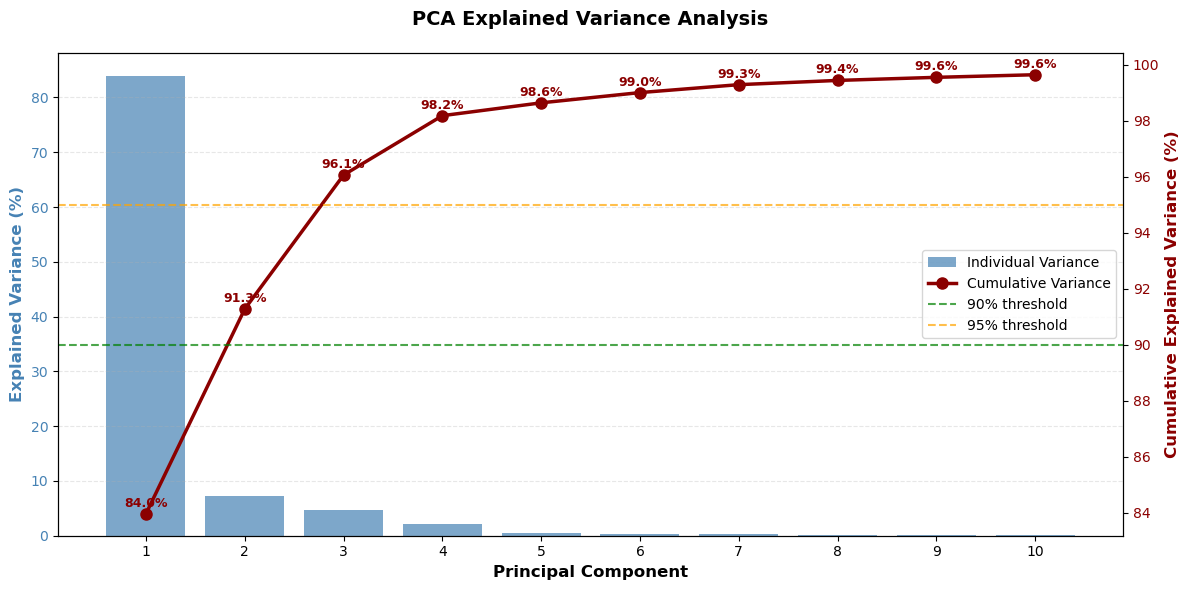

In [29]:
# CREATE VARIANCE PLOT
# Extract variance data
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
component_numbers = np.arange(1, n_components + 1)

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar plot for individual explained variance
color_bars = 'steelblue'
ax1.bar(component_numbers, explained_variance * 100, 
        alpha=0.7, color=color_bars, label='Individual Variance')
ax1.set_xlabel('Principal Component', fontsize=12, fontweight='bold')
ax1.set_ylabel('Explained Variance (%)', fontsize=12, fontweight='bold', color=color_bars)
ax1.tick_params(axis='y', labelcolor=color_bars)
ax1.set_xticks(component_numbers)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Line plot for cumulative variance
ax2 = ax1.twinx()
color_line = 'darkred'
ax2.plot(component_numbers, cumulative_variance * 100, 
         marker='o', linewidth=2.5, markersize=8, 
         color=color_line, label='Cumulative Variance')
ax2.set_ylabel('Cumulative Explained Variance (%)', 
               fontsize=12, fontweight='bold', color=color_line)
ax2.tick_params(axis='y', labelcolor=color_line)

# Add horizontal line at 90% and 95%
ax2.axhline(y=90, color='green', linestyle='--', linewidth=1.5, alpha=0.7, label='90% threshold')
ax2.axhline(y=95, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='95% threshold')

# Add value labels on the cumulative line
for i, (x, y) in enumerate(zip(component_numbers, cumulative_variance * 100)):
    ax2.annotate(f'{y:.1f}%', 
                xy=(x, y), 
                xytext=(0, 5),
                textcoords='offset points',
                ha='center', 
                fontsize=9,
                color=color_line,
                fontweight='bold')

# Title and legends
plt.title('PCA Explained Variance Analysis', fontsize=14, fontweight='bold', pad=20)

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='center right', fontsize=10)

plt.tight_layout()
plt.savefig('pca_explained_variance.png', dpi=300, bbox_inches='tight')
print("\n✓ Variance plot saved to 'pca_explained_variance.png'")
plt.show()



Testing k=20...
Plotting elbow graph...                    


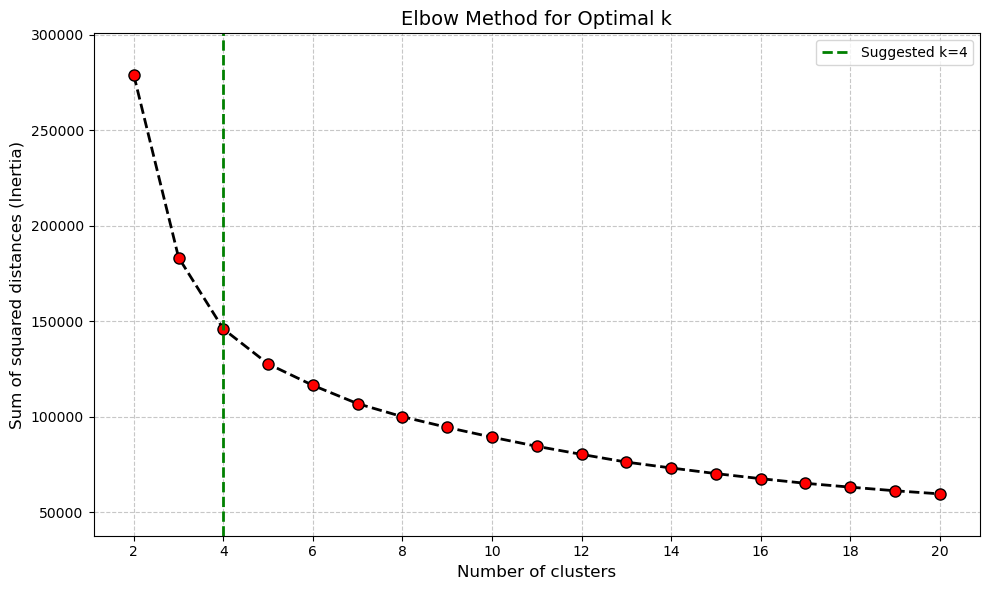

In [36]:
# Elbow Method
sum_squared_distance = []
range_n_clusters = range(2, 21)

for k in range_n_clusters:
    print(f"Testing k={k}...", end='\r')
    clusterer = cluster.KMeans(n_clusters=k, random_state=1, n_init=10)
    clusterer.fit(selected_components)
    sum_squared_distance.append(clusterer.inertia_)

print("\nPlotting elbow graph...                    ")
range_ssd = max(sum_squared_distance) - min(sum_squared_distance)

plt.figure(figsize=(10, 6))
plt.plot(range_n_clusters, sum_squared_distance, 'ko--', mfc='r', linewidth=2, markersize=8)
plt.vlines(x=4, ymin=min(sum_squared_distance)-(0.1*range_ssd),
           ymax=max(sum_squared_distance)+(0.1*range_ssd), color='g', linestyles='dashed', 
           linewidth=2, label='Suggested k=4')
plt.xticks(range(2, 21, 2))
plt.ylim(min(sum_squared_distance)-(0.1*range_ssd), max(sum_squared_distance)+(0.1*range_ssd))
plt.xlabel('Number of clusters', fontsize=12)
plt.ylabel('Sum of squared distances (Inertia)', fontsize=12)
plt.title('Elbow Method for Optimal k', fontsize=14)
plt.legend()
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('pca_elbow.png', dpi=300, bbox_inches='tight')
plt.show()

In [32]:
# K-Means Clustering
n_clusters = 4  # Adjust based on elbow graph
print(f"Using k={n_clusters} clusters")

clusterer = cluster.KMeans(n_clusters=n_clusters, random_state=1, n_init=10)
pred = clusterer.fit_predict(selected_components)
labels = clusterer.labels_

# Clustering metrics
ch_score = calinski_harabasz_score(selected_components, labels)
db_score = davies_bouldin_score(selected_components, labels)

print(f'\nClustering Metrics:')
print(f'  Calinski-Harabasz score: {ch_score:.4f} (higher is better)')
print(f'  Davies-Bouldin score: {db_score:.4f} (lower is better)')

# Cluster distribution
print(f'\nCluster distribution:')
for i in range(n_clusters):
    count = np.sum(labels == i)
    pct = 100 * count / len(labels)
    print(f'  Cluster {i}: {count:,} pixels ({pct:.2f}%)')

# Reshape labels back to spatial dimensions
labels_full = np.full(rows * cols, np.nan)
labels_full[valid_mask_full] = labels
labels_spatial = labels_full.reshape(rows, cols)

valid_spatial_pixels = np.sum(~np.isnan(labels_spatial))
print(f"Valid pixels in spatial array: {valid_spatial_pixels:,}")

# Apply majority filter
print("\nApplying majority filter (7×7)...")

def filter_function(invalues):
    valid_values = invalues[~np.isnan(invalues)]
    if len(valid_values) == 0:
        return np.nan
    result = mode(valid_values, keepdims=True)
    return result[0][0]

labels_major = generic_filter(labels_spatial, function=filter_function, size=7, 
                              mode='constant', cval=np.nan)

print("Majority filter applied successfully!")

Using k=4 clusters

Clustering Metrics:
  Calinski-Harabasz score: 1044189.2757 (higher is better)
  Davies-Bouldin score: 0.9809 (lower is better)

Cluster distribution:
  Cluster 0: 306,591 pixels (29.36%)
  Cluster 1: 380,579 pixels (36.45%)
  Cluster 2: 100,607 pixels (9.64%)
  Cluster 3: 256,326 pixels (24.55%)
Valid pixels in spatial array: 1,044,103

Applying majority filter (7×7)...
Majority filter applied successfully!


In [33]:
# Plotting function
def plot_map(array, extent, n_clusters, title='K-Means Clustering Results', filename=None):
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    plt.yticks(rotation=90, va='center')
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    
    cmap = cm.get_cmap('rainbow', n_clusters)
    im = plt.imshow(array, cmap=cmap, extent=extent, interpolation='nearest')
    
    cbar = plt.colorbar(im, label='Cluster Number', shrink=0.8)
    tick_locs = (np.arange(n_clusters) + 0.5) * (n_clusters - 1) / n_clusters
    cbar.set_ticks(tick_locs)
    cbar.set_ticklabels(np.arange(n_clusters))
    
    plt.grid(False)
    plt.xlabel('Longitude (°E)', fontsize=12)
    plt.ylabel('Latitude (°S)', fontsize=12)
    plt.title(title, fontsize=14)
    plt.tight_layout()
    
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
    
    return fig, ax

Plotting original clustering...


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_1772/3377784106.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow', n_clusters)


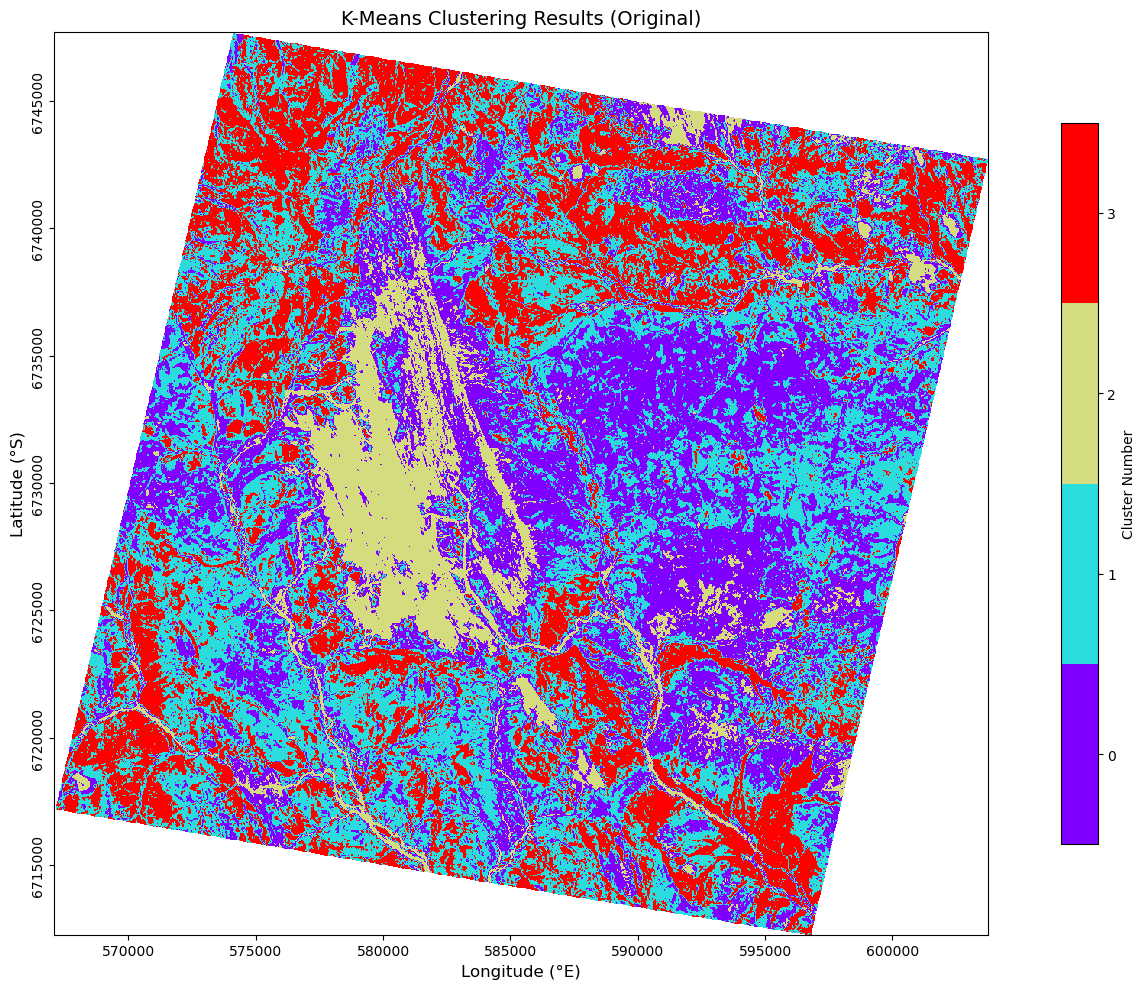

Plotting filtered clustering...


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_1772/3377784106.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow', n_clusters)


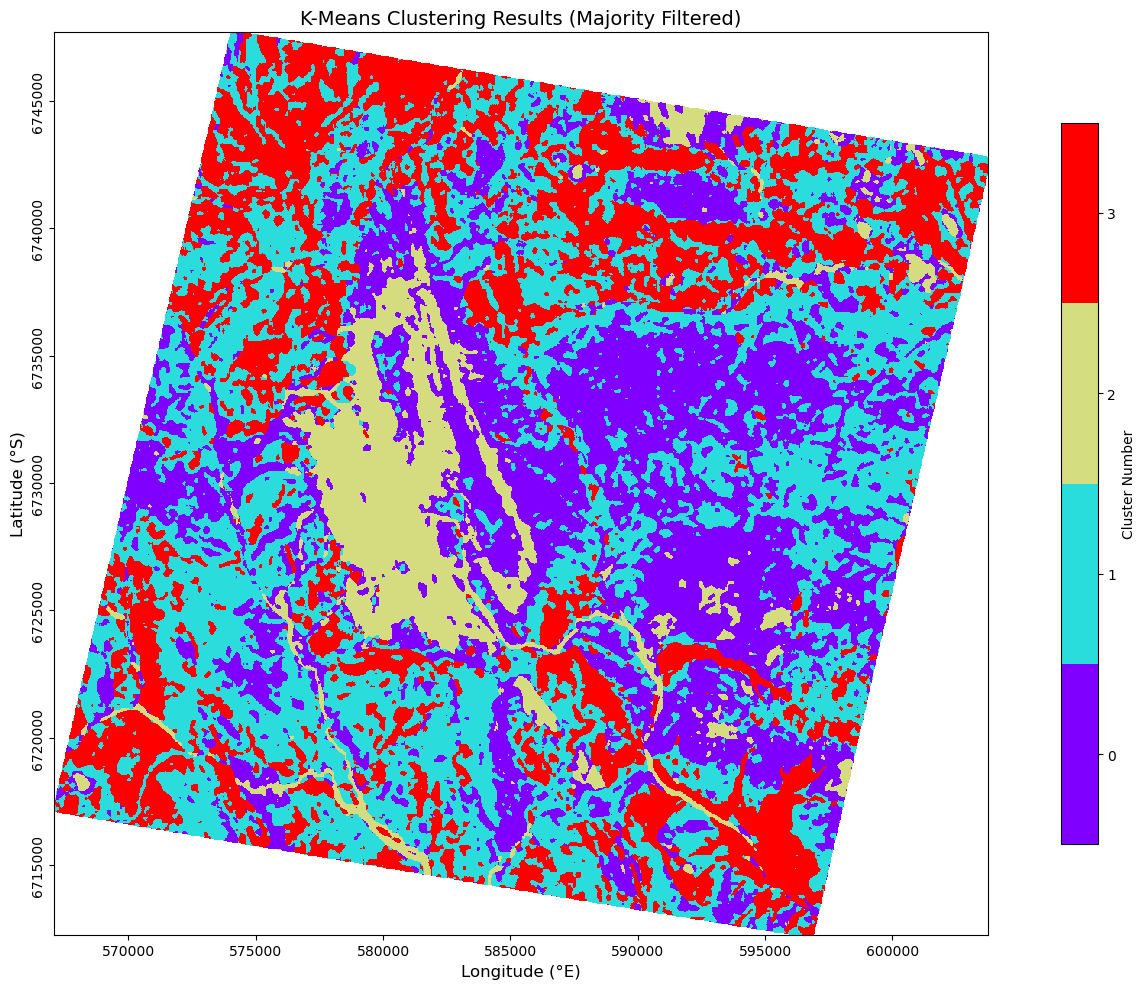

In [34]:
# Plot results
print("Plotting original clustering...")
fig1, ax1 = plot_map(labels_spatial, extent, n_clusters, 
                     title='K-Means Clustering Results (Original)',
                     filename='clustering_original.png')
plt.show()

print("Plotting filtered clustering...")
fig2, ax2 = plot_map(labels_major, extent, n_clusters, 
                     title='K-Means Clustering Results (Majority Filtered)',
                     filename='clustering_filtered.png')
plt.show()

In [35]:
# SAVE FOR EVALUATION
np.save('pca_encoded_data.npy', selected_components)
np.save('pca_labels_spatial.npy', labels_major)
print(f"✓ Saved PCA results")

✓ Saved PCA results
